# Análise exploratória dos dados

Decks de Modern do MTGO (recorte definido em `config.yaml`) e cartas do Scryfall. Rode antes `python -m data.download` e `python -m src.load`. As figuras são salvas em `results/eda_*.png`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import load_config

cfg = load_config(ROOT / "config.yaml")
P, R = Path(cfg["paths"]["processed"]), Path(cfg["paths"]["results"])
decks = pd.read_parquet(P / "decks.parquet")
meta = pd.read_parquet(P / "deck_meta.parquet")
catalog = pd.read_parquet(P / "catalog.parquet")
report = json.loads((P / "load_report.json").read_text(encoding="utf-8"))

# Chart style: one series color, muted text, recessive grid, no top/right spines.
BLUE, INK, MUTED, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "font.size": 10, "figure.dpi": 110,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(R / f"eda_{name}.png", dpi=150)
    plt.show()

## 1. Tamanho do dataset e esparsidade

In [2]:
n_decks, n_items, n_inter = meta.shape[0], catalog.shape[0], decks.shape[0]
summary = pd.DataFrame({
    "valor": [n_decks, n_items, n_inter, f"{100 * (1 - n_inter / (n_decks * n_items)):.2f}%",
              f"{report['window_start_exclusive']} → {report['window_end']}"],
}, index=["decks (usuários)", "cartas no catálogo (itens)", "interações (deck × carta)",
          "esparsidade", "janela (início exclusivo → fim)"])
summary

,valor
decks (usuários),10460
cartas no catálogo (itens),1772
interações (deck × carta),226824
esparsidade,98.78%
janela (início exclusivo → fim),2026-05-08 → 2026-11-08


## 2. Filtros aplicados e cartas não casadas

In [3]:
filters = pd.Series({
    "decks de Modern no cache": report["decks_in_format_total"],
    "decks na janela de tempo": report["decks_in_window"],
    "removidos: < min_main_cards": report["decks_removed_small"],
    "removidos: duplicata exata": report["decks_removed_duplicate"],
    "decks finais": report["decks_kept"],
    "nomes distintos na janela": report["distinct_names_in_window"],
    "nomes resolvidos por alias do MTGO": len(report["aliases_resolved"]),
    "nomes não casados com o Scryfall": report["unmatched_distinct"],
}, name="quantidade").to_frame()
filters

,quantidade
decks de Modern no cache,21526
decks na janela de tempo,20837
removidos: < min_main_cards,0
removidos: duplicata exata,10377
decks finais,10460
nomes distintos na janela,1788
nomes resolvidos por alias do MTGO,15
nomes não casados com o Scryfall,0


In [4]:
pd.read_csv(R / "unmatched_cards.csv")

,card_name,copies_in_window


## 3. Cartas distintas (não-básicas) por deck

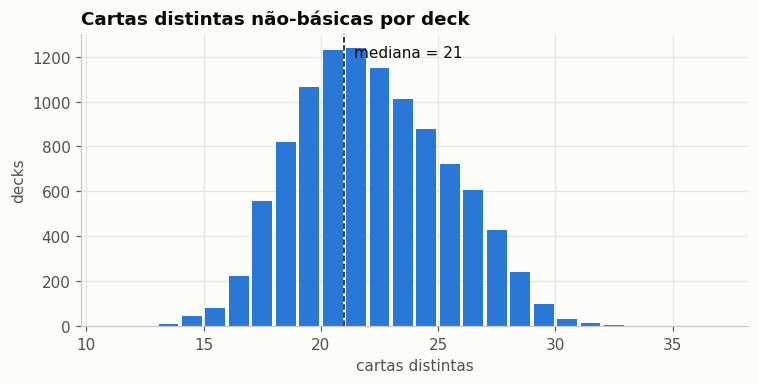

count    10460.00
mean        21.68
std          3.20
min         11.00
25%         19.00
50%         21.00
75%         24.00
max         36.00
dtype: float64

In [5]:
per_deck = decks.groupby("deck_id").size()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(per_deck, bins=range(per_deck.min(), per_deck.max() + 2), color=BLUE, rwidth=0.85)
ax.axvline(per_deck.median(), color=INK, lw=1, ls="--")
ax.text(per_deck.median() + 0.4, ax.get_ylim()[1] * 0.92, f"mediana = {per_deck.median():.0f}", color=INK)
ax.set(title="Cartas distintas não-básicas por deck", xlabel="cartas distintas", ylabel="decks")
save(fig, "cards_per_deck")
per_deck.describe().round(2)

## 4. Popularidade: 20 cartas mais frequentes e cauda longa

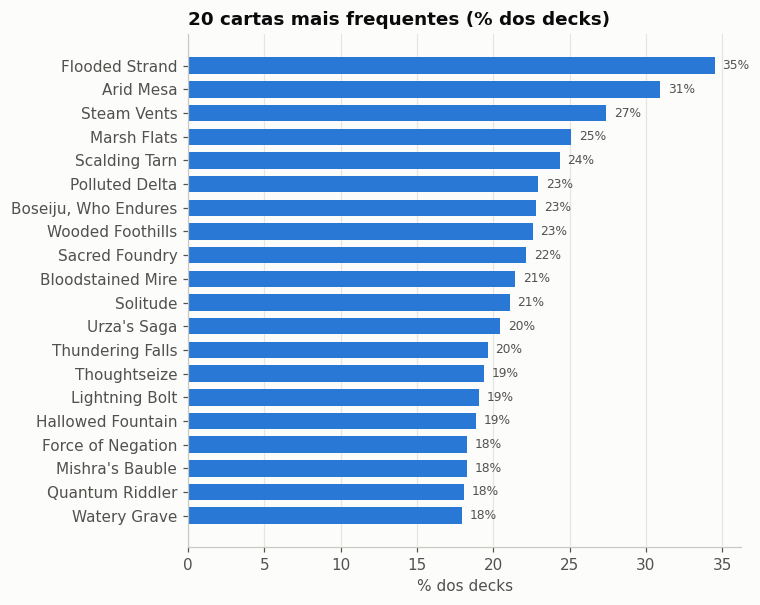

In [6]:
pop = decks.groupby("card_name")["deck_id"].nunique().sort_values(ascending=False)
top = (pop.head(20) / n_decks * 100)[::-1]
fig, ax = plt.subplots(figsize=(7, 5.6))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
ax.grid(axis="y", visible=False)
for y, v in enumerate(top.values):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", color=MUTED, fontsize=8)
ax.set(title="20 cartas mais frequentes (% dos decks)", xlabel="% dos decks")
save(fig, "top20")

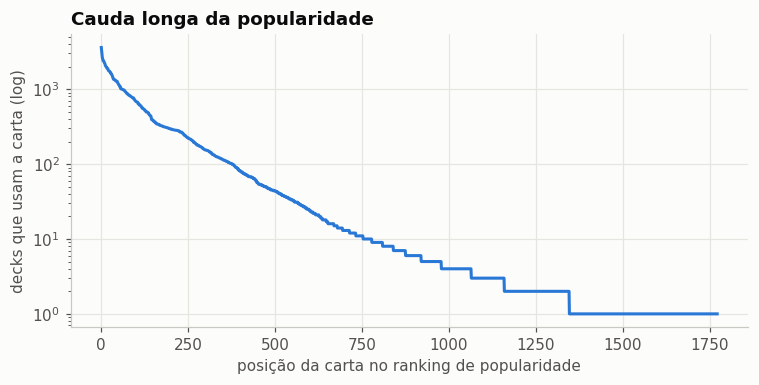

212 cartas (12.0% do catálogo) respondem por 80% das interações; 426 cartas aparecem em um único deck.


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(np.arange(1, len(pop) + 1), pop.values, color=BLUE, lw=2)
ax.set_yscale("log")
ax.set(title="Cauda longa da popularidade", xlabel="posição da carta no ranking de popularidade",
       ylabel="decks que usam a carta (log)")
save(fig, "long_tail")
share = pop.cumsum() / pop.sum()
print(f"{(share <= 0.8).sum()} cartas ({100 * (share <= 0.8).mean():.1f}% do catálogo) "
      f"respondem por 80% das interações; {(pop == 1).sum()} cartas aparecem em um único deck.")

## 5. Cores, tipos e custo de mana do catálogo

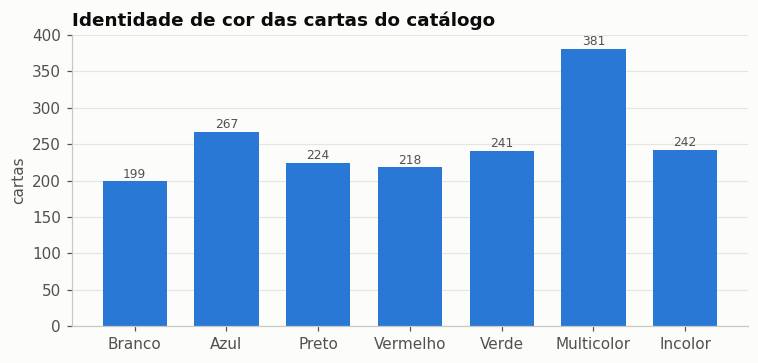

In [8]:
def color_group(ci):
    ci = list(ci)
    return "Incolor" if not ci else ("Multicolor" if len(ci) > 1 else ci[0])

names = {"W": "Branco", "U": "Azul", "B": "Preto", "R": "Vermelho", "G": "Verde"}
groups = catalog["color_identity"].map(color_group).replace(names)
order = ["Branco", "Azul", "Preto", "Vermelho", "Verde", "Multicolor", "Incolor"]
counts = groups.value_counts().reindex(order, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(counts.index, counts.values, color=BLUE, width=0.7)
ax.grid(axis="x", visible=False)
for x, v in enumerate(counts.values):
    ax.text(x, v + 5, str(v), ha="center", color=MUTED, fontsize=8)
ax.set(title="Identidade de cor das cartas do catálogo", ylabel="cartas")
save(fig, "colors")

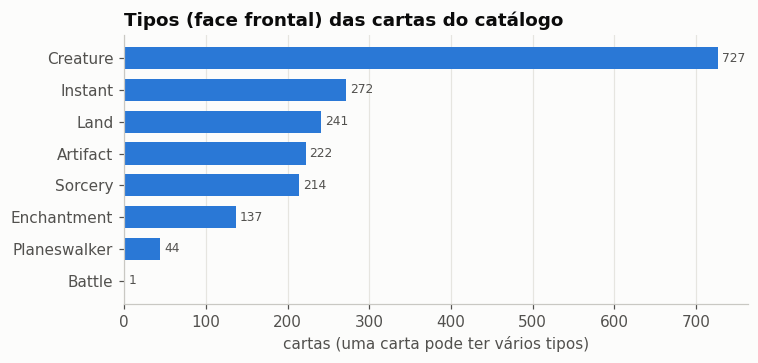

In [9]:
MAIN_TYPES = ["Creature", "Instant", "Sorcery", "Artifact", "Enchantment", "Planeswalker", "Land", "Battle"]
front_types = catalog["type_line"].str.split(" // ").str[0].str.split("—").str[0]
type_counts = pd.Series({t: front_types.str.contains(t).sum() for t in MAIN_TYPES}).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(type_counts.index, type_counts.values, color=BLUE, height=0.7)
ax.grid(axis="y", visible=False)
for y, v in enumerate(type_counts.values):
    ax.text(v + 5, y, str(v), va="center", color=MUTED, fontsize=8)
ax.set(title="Tipos (face frontal) das cartas do catálogo", xlabel="cartas (uma carta pode ter vários tipos)")
save(fig, "types")

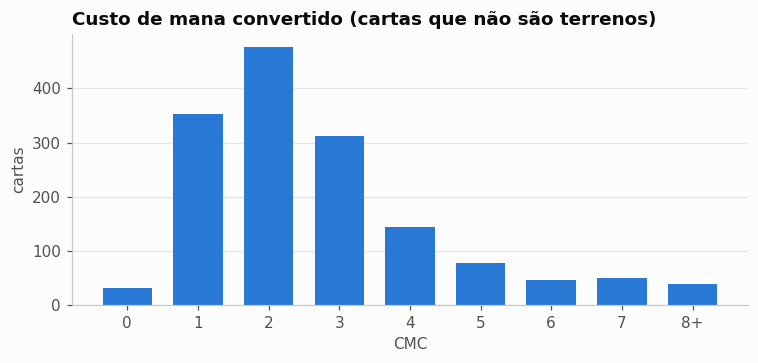

In [10]:
nonland = catalog[~front_types.str.contains("Land")]
cmc = nonland["cmc"].clip(upper=8).astype(int)
cmc_counts = cmc.value_counts().reindex(range(0, 9), fill_value=0)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(cmc_counts.index, cmc_counts.values, color=BLUE, width=0.7)
ax.grid(axis="x", visible=False)
ax.set_xticks(range(0, 9), [str(i) for i in range(8)] + ["8+"])
ax.set(title="Custo de mana convertido (cartas que não são terrenos)", xlabel="CMC", ylabel="cartas")
save(fig, "cmc")

## 6. Tamanho do texto de regras

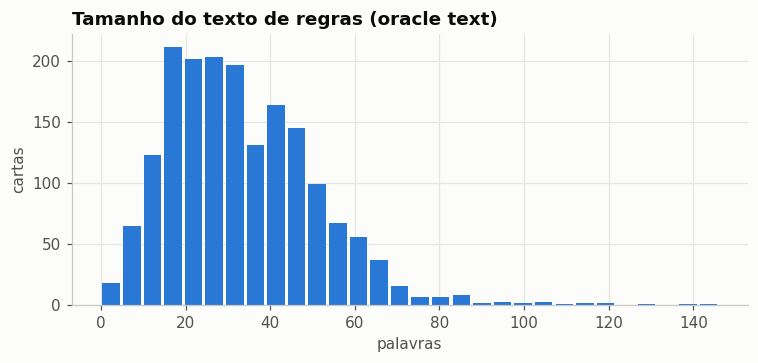

cartas sem texto de regras: 2


count    1772.0
mean       33.5
std        17.9
min         0.0
25%        20.0
50%        31.0
75%        44.0
max       146.0
Name: oracle_text, dtype: float64

In [11]:
words = catalog["oracle_text"].fillna("").str.split().str.len()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(words, bins=30, color=BLUE, rwidth=0.85)
ax.set(title="Tamanho do texto de regras (oracle text)", xlabel="palavras", ylabel="cartas")
save(fig, "text_length")
print(f"cartas sem texto de regras: {(words == 0).sum()}")
words.describe().round(1)